In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = Path.cwd().parent
DATA_DIR = BASE_DIR / "data"

## MIPD

In [9]:
train = pd.read_csv(DATA_DIR / "MIPD" / "train.csv", encoding="utf-8")
val = pd.read_csv(DATA_DIR / "MIPD" / "validation.csv", encoding="utf-8")
test = pd.read_csv(DATA_DIR / "MIPD" / "test.csv", encoding="utf-8")

In [10]:
print("train shape:", train.shape)
print("val shape:", val.shape)
print("test shape:", test.shape)
print(train.columns)
train.head(2)

train shape: (10749, 12)
val shape: (3086, 12)
test shape: (1521, 12)
Index(['article', 'REFERENCE_ERROR', 'WHATABOUTISM', 'STRAWMAN',
       'EMOTIONAL_CONTENT', 'CHERRY_PICKING', 'FALSE_CAUSE',
       'MISLEADING_CLICKBAI', 'ANECDOTE', 'LEADING_QUESTIONS', 'EXAGGERATION',
       'QUOTE_MINING'],
      dtype='object')


,article,REFERENCE_ERROR,WHATABOUTISM,STRAWMAN,EMOTIONAL_CONTENT,CHERRY_PICKING,FALSE_CAUSE,MISLEADING_CLICKBAI,ANECDOTE,LEADING_QUESTIONS,EXAGGERATION,QUOTE_MINING
0,"""Terapia homoseksualizmu – szansa czy oszustwo...",False,False,False,False,False,True,False,True,False,False,False
1,"""Ukrainofile, idi na ch…! – Katarzyna TS"" ""W n...",False,True,False,False,True,False,False,False,False,True,False


In [11]:
label_cols = [c for c in train.columns if c != "article"]
splits = {"train": train, "val": val, "test": test}

# positive count and share per label, per split
counts = pd.DataFrame({name: df[label_cols].sum() for name, df in splits.items()})
shares = pd.DataFrame({name: df[label_cols].mean() for name, df in splits.items()})
counts = counts.sort_values("train", ascending=False)
shares = shares.loc[counts.index]
pd.concat({"count": counts, "share": shares.round(3)}, axis=1)

count            share              
                    train  val test  train    val   test
EXAGGERATION         1514  405  234  0.141  0.131  0.154
CHERRY_PICKING       1082  295  149  0.101  0.096  0.098
REFERENCE_ERROR       762  227  119  0.071  0.074  0.078
EMOTIONAL_CONTENT     635  182   92  0.059  0.059  0.060
FALSE_CAUSE           627  193   95  0.058  0.063  0.062
STRAWMAN              321   76   37  0.030  0.025  0.024
ANECDOTE              310   88   44  0.029  0.029  0.029
WHATABOUTISM          307   82   37  0.029  0.027  0.024
MISLEADING_CLICKBAI   123   41   13  0.011  0.013  0.009
LEADING_QUESTIONS      92   20   15  0.009  0.006  0.010
QUOTE_MINING           88   23   14  0.008  0.007  0.009

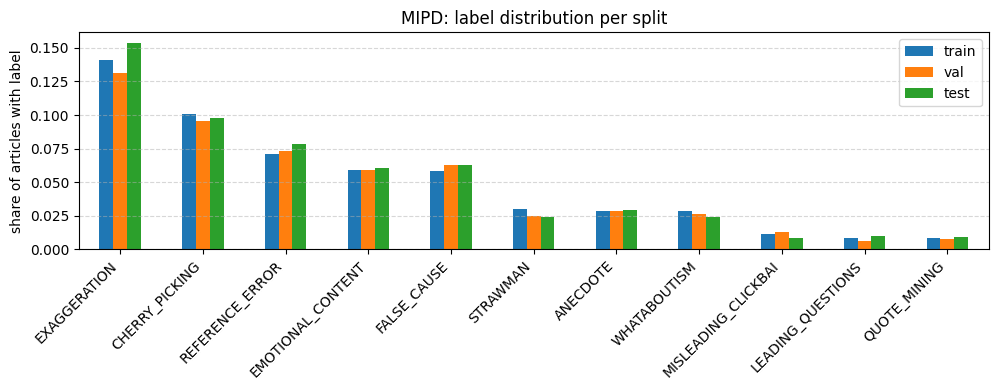

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
shares.plot.bar(ax=ax)
ax.set_ylabel("share of articles with label")
ax.set_title("MIPD: label distribution per split")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

share of articles with no label: {'train': 0.758, 'val': 0.765, 'test': 0.755}


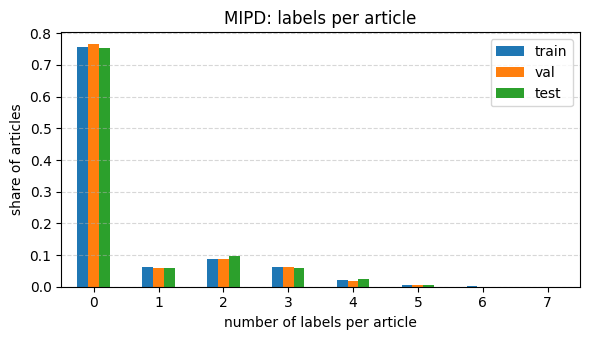

In [13]:
# multi-label: how many techniques per article
n_labels = pd.DataFrame({name: df[label_cols].sum(axis=1).value_counts(normalize=True) for name, df in splits.items()}).sort_index()
print("share of articles with no label:", {name: round(float((df[label_cols].sum(axis=1) == 0).mean()), 3) for name, df in splits.items()})

fig, ax = plt.subplots(figsize=(6, 3.5))
n_labels.plot.bar(ax=ax)
ax.set_xlabel("number of labels per article")
ax.set_ylabel("share of articles")
ax.set_title("MIPD: labels per article")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

count    10749.0
mean       764.5
std        911.4
min         19.0
25%        347.0
50%        544.0
75%        906.0
max      25018.0
Name: article, dtype: float64


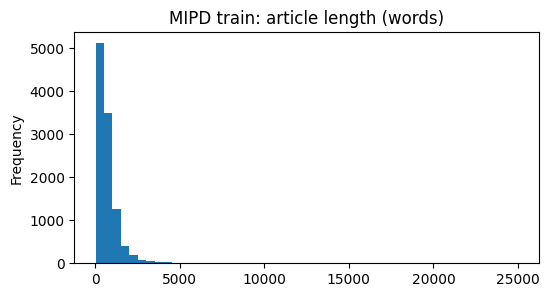

In [14]:
# article length in words
lengths = train["article"].str.split().str.len()
print(lengths.describe().round(1))
lengths.plot.hist(bins=50, figsize=(6, 3), title="MIPD train: article length (words)")
plt.show()

## SemEval2023 task 3

In [15]:
def read_tsv(path, names):
    # split on the first two tabs only; lines with no labels have an empty third field
    rows = []
    with path.open(encoding="utf-8") as f:
        for line in f:
            parts = line.rstrip("\n").split("\t", 2)
            rows.append(parts + [""] * (3 - len(parts)))
    return pd.DataFrame(rows, columns=names)


def load_semeval(split):
    semeval_dir = DATA_DIR / "SemEval23"
    labels = read_tsv(semeval_dir / f"{split}-labels-subtask-3.txt", ["article_id", "par_id", "labels"])
    texts = read_tsv(semeval_dir / f"{split}-labels-subtask-3.template", ["article_id", "par_id", "text"])
    df = labels.merge(texts, on=["article_id", "par_id"], how="left")
    df["labels"] = df["labels"].apply(lambda s: s.split(",") if s else [])
    return df


sem = {split: load_semeval(split) for split in ["train", "dev"]}  # test has no gold labels
for split, df in sem.items():
    print(f"{split}: {len(df)} paragraphs, {df.article_id.nunique()} articles, {df.text.isna().sum()} without text")
sem["train"].head()

train: 2310 paragraphs, 145 articles, 16 without text
dev: 800 paragraphs, 49 articles, 0 without text


,article_id,par_id,labels,text
0,251,1,[Exaggeration-Minimisation],Nord Stream 2 największym problemem niemieckie...
1,251,3,"[Appeal_to_Fear-Prejudice, Exaggeration-Minimi...",Gazociąg Nord Stream 2 i wiążąca się z nim zal...
2,251,5,[],Taka zależność istniała już w czasie zimnej wo...
3,251,7,[],"Niemcy potrzebują rosyjskiego gazu, a Rosja ni..."
4,251,9,"[Loaded_Language, Questioning_the_Reputation]",„Rosja od dawna realizuje strategię podziału U...


In [16]:
sem_counts = pd.DataFrame({split: df["labels"].explode().value_counts() for split, df in sem.items()}).fillna(0).astype(int)
sem_shares = pd.DataFrame({split: sem_counts[split] / len(df) for split, df in sem.items()})
sem_counts = sem_counts.sort_values("train", ascending=False)
sem_shares = sem_shares.loc[sem_counts.index]
print("number of techniques:", len(sem_counts))
pd.concat({"count": sem_counts, "share": sem_shares.round(3)}, axis=1)

number of techniques: 23


count       share       
                                 train  dev  train    dev
labels                                                   
Name_Calling-Labeling              475  111  0.206  0.139
Loaded_Language                    310   93  0.134  0.116
Doubt                              295   96  0.128  0.120
Questioning_the_Reputation         164   57  0.071  0.071
Appeal_to_Hypocrisy                162   76  0.070  0.095
Exaggeration-Minimisation          111   40  0.048  0.050
Appeal_to_Fear-Prejudice           108   36  0.047  0.045
Appeal_to_Values                   101   50  0.044  0.062
Guilt_by_Association                94   30  0.041  0.038
Flag_Waving                         68   28  0.029  0.035
Conversation_Killer                 50   40  0.022  0.050
Appeal_to_Authority                 41   40  0.018  0.050
Obfuscation-Vagueness-Confusion     36   11  0.016  0.014
Slogans                             36    7  0.016  0.009
Appeal_to_Popularity                30   22  0.013  0.028
Consequential_Oversimplification    24    8  0.010  0.010
Straw_Man                           15    3  0.006  0.004
Appeal_to_Time                      14    5  0.006  0.006
Repetition                          13   10  0.006  0.012
False_Dilemma-No_Choice             12    8  0.005  0.010
Red_Herring                         12    7  0.005  0.009
Causal_Oversimplification           12    5  0.005  0.006
Whataboutism                         8    3  0.003  0.004

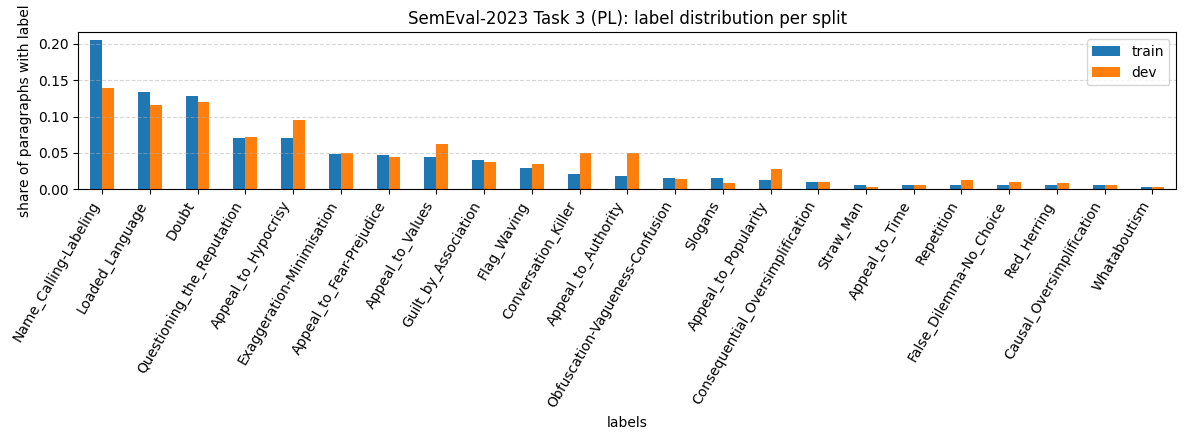

In [17]:
fig, ax = plt.subplots(figsize=(12, 4.5))
sem_shares.plot.bar(ax=ax)
ax.set_ylabel("share of paragraphs with label")
ax.set_title("SemEval-2023 Task 3 (PL): label distribution per split")
plt.xticks(rotation=60, ha="right")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

share of paragraphs with no label: {'train': 0.467, 'dev': 0.471}


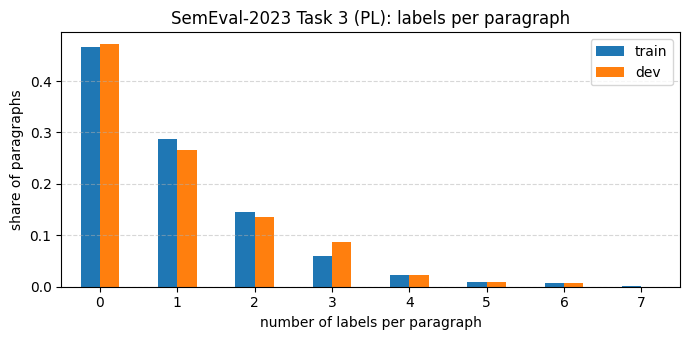

In [18]:
sem_n_labels = pd.DataFrame({split: df["labels"].str.len().value_counts(normalize=True) for split, df in sem.items()}).sort_index().fillna(0)
print("share of paragraphs with no label:", {split: round(float((df["labels"].str.len() == 0).mean()), 3) for split, df in sem.items()})

fig, ax = plt.subplots(figsize=(7, 3.5))
sem_n_labels.plot.bar(ax=ax)
ax.set_xlabel("number of labels per paragraph")
ax.set_ylabel("share of paragraphs")
ax.set_title("SemEval-2023 Task 3 (PL): labels per paragraph")
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

count    2294.0
mean       46.6
std        42.8
min         1.0
25%        19.0
50%        40.0
75%        62.8
max       615.0
Name: text, dtype: float64


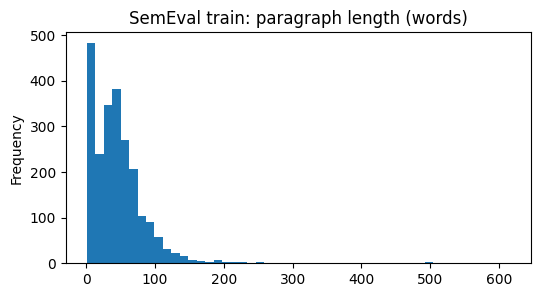

In [19]:
# paragraph length in words
sem_lengths = sem["train"]["text"].dropna().str.split().str.len()
print(sem_lengths.describe().round(1))
sem_lengths.plot.hist(bins=50, figsize=(6, 3), title="SemEval train: paragraph length (words)")
plt.show()